In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import chi2
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

df = pd.read_csv("data/train.csv")

In [13]:
cols_to_drop = ['Unnamed: 0', 'id']
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])
for col in df.columns:
    if df[col].isna().sum() > 0:
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

df = df.drop_duplicates()

In [14]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df_numeric = df[numeric_cols].copy()

constant_cols = [col for col in df_numeric.columns if df_numeric[col].std() == 0]
df_numeric = df_numeric.drop(columns=constant_cols)

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_numeric)
df_scaled = pd.DataFrame(scaled_data, columns=df_numeric.columns)

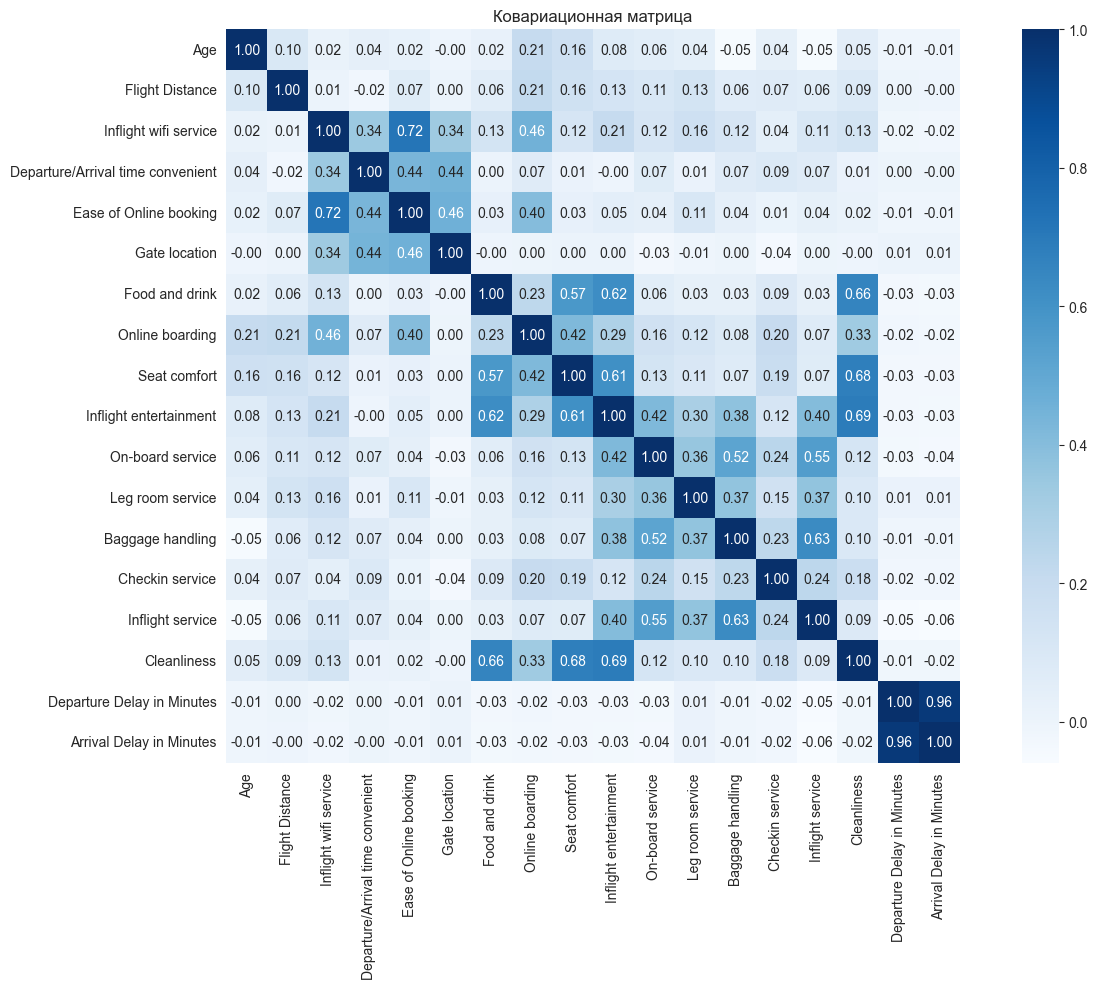

In [15]:
plt.figure(figsize=(14, 10))
sns.heatmap(df_scaled.cov(), annot=True, cmap='Blues', fmt='.2f', square=True)
plt.title('Ковариационная матрица')
plt.tight_layout()
plt.show()

In [16]:
def bartlett_sphericity(df):
    corr = df.corr().values
    n = df.shape[0]
    p = df.shape[1]
    det_corr = np.linalg.det(corr)
    chi2_stat = - (n - 1 - (2*p + 5)/6) * np.log(det_corr)
    df_chi2 = p * (p - 1) // 2
    p_value = 1 - chi2.cdf(chi2_stat, df_chi2)
    return chi2_stat, p_value

def calculate_kmo(df):
    corr = df.corr().values
    inv_corr = np.linalg.inv(corr)
    n_features = df.shape[1]
    kmo_numer = np.zeros(n_features)
    kmo_denom = np.zeros(n_features)
    for i in range(n_features):
        for j in range(n_features):
            if i != j:
                kmo_numer[i] += corr[i, j]**2
                kmo_denom[i] += corr[i, j]**2 + inv_corr[i, j]**2
    kmo_total = np.sum(kmo_numer) / np.sum(kmo_denom)
    return kmo_total

chi2_value, p_value = bartlett_sphericity(df_scaled)
kmo_total = calculate_kmo(df_scaled)

print(f"Критерий Бартлетта: хи-квадрат = {chi2_value:.2f}, p-value = {p_value:.10f}")
print(f"KMO: {kmo_total:.4f}")

Критерий Бартлетта: хи-квадрат = 886552.68, p-value = 0.0000000000
KMO: 0.0489


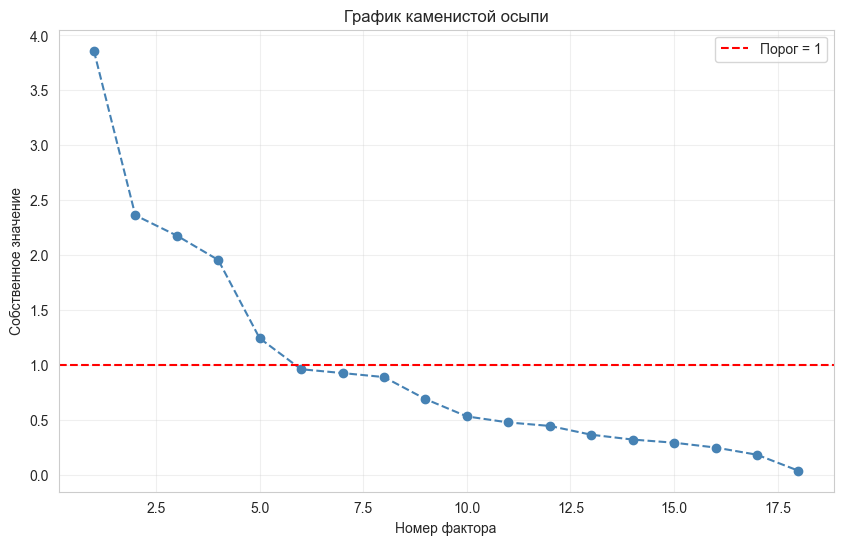

Рекомендуемое число факторов: 5


In [17]:
pca_full = PCA()
pca_full.fit(df_scaled)
eigenvalues = pca_full.explained_variance_

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(eigenvalues)+1), eigenvalues, 'o--', color='steelblue')
plt.axhline(y=1, color='red', linestyle='--', label='Порог = 1')
plt.title('График каменистой осыпи')
plt.xlabel('Номер фактора')
plt.ylabel('Собственное значение')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

n_factors = sum(eigenvalues > 1)
print(f"Рекомендуемое число факторов: {n_factors}")

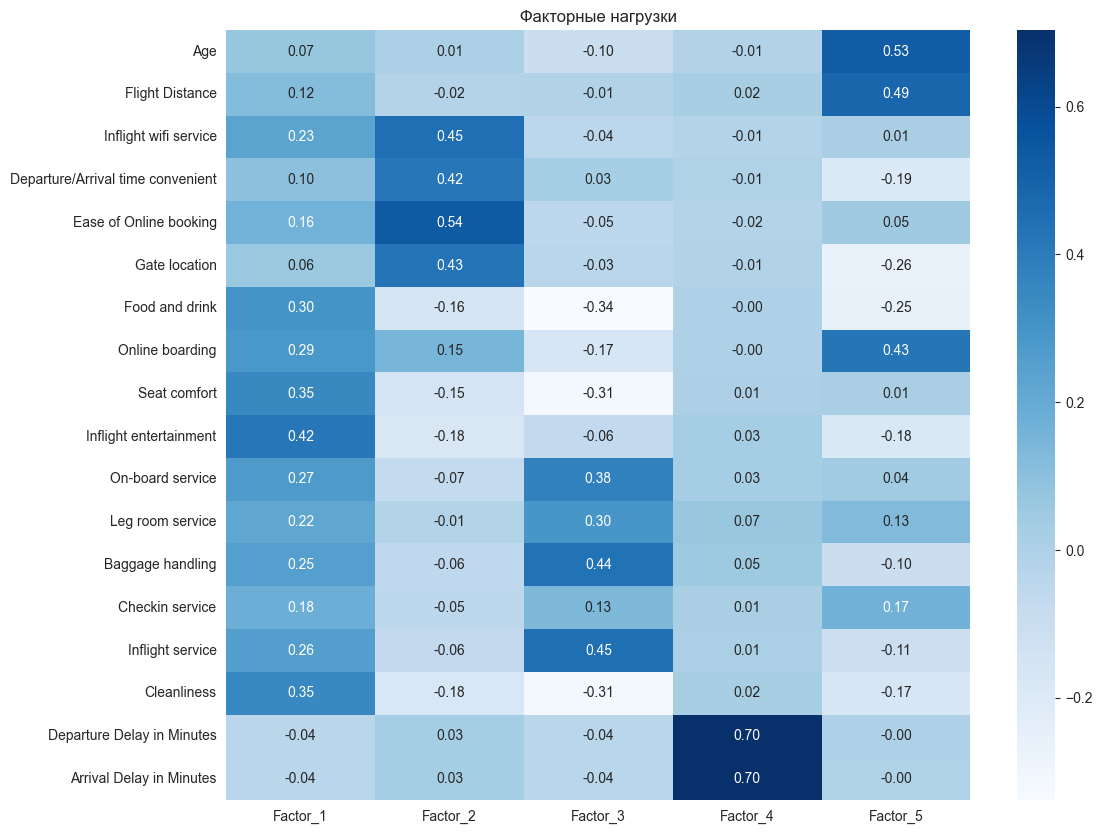

In [18]:
pca = PCA(n_components=n_factors)
pca.fit(df_scaled)

loadings = pca.components_.T
loadings_df = pd.DataFrame(
    loadings,
    index=df_scaled.columns,
    columns=[f'Factor_{i+1}' for i in range(n_factors)]
)

plt.figure(figsize=(12, max(8, n_factors * 2)))
sns.heatmap(loadings_df, annot=True, cmap='Blues', fmt='.2f')
plt.title('Факторные нагрузки')
plt.show()

In [19]:
explained_variance = pca.explained_variance_ratio_
cumulative = np.cumsum(explained_variance)

for i in range(n_factors):
    print(f"Фактор {i+1}: {explained_variance[i]:.4f} (кумулятивно: {cumulative[i]:.4f})")

factor_scores = pca.transform(df_scaled)
print("\nФакторные значения:")
print(pd.DataFrame(factor_scores[:10], columns=[f'Factor_{i+1}' for i in range(n_factors)]).round(4))

Фактор 1: 0.2145 (кумулятивно: 0.2145)
Фактор 2: 0.1313 (кумулятивно: 0.3458)
Фактор 3: 0.1211 (кумулятивно: 0.4668)
Фактор 4: 0.1087 (кумулятивно: 0.5756)
Фактор 5: 0.0692 (кумулятивно: 0.6447)

Факторные значения:
   Factor_1  Factor_2  Factor_3  Factor_4  Factor_5
0    2.1064   -1.2379   -0.2305    0.3409   -1.9117
1   -3.3230    1.2431    1.2570   -0.5432   -0.0890
2    2.1289   -1.9274   -0.9108   -0.4257   -0.3950
3   -1.8683    2.5003    0.8470   -0.2789   -1.3946
4    0.7831    0.2378   -0.9407   -0.5647    0.8322
5   -2.5929    0.3367    2.5382   -0.5666    0.4989
6   -1.6056    0.1992    1.6168   -0.0103    0.0775
7    3.8166    0.4223    0.4602   -0.2532    0.6759
8   -3.3702   -0.7054   -2.4414   -0.8442    0.7964
9   -1.4853    1.0687    0.4090   -0.6308   -0.3808


In [20]:
for i in range(n_factors):
    factor_col = f'Factor_{i+1}'
    print(f"\nФактор {i+1}:")
    sorted_loadings = loadings_df[factor_col].abs().sort_values(ascending=False).head(5)
    for var, val in sorted_loadings.items():
        actual = loadings_df.loc[var, factor_col]
        print(f"  {var}: {actual:.4f}")


Фактор 1:
  Inflight entertainment: 0.4221
  Cleanliness: 0.3517
  Seat comfort: 0.3457
  Food and drink: 0.3022
  Online boarding: 0.2871

Фактор 2:
  Ease of Online booking: 0.5364
  Inflight wifi service: 0.4496
  Gate location: 0.4302
  Departure/Arrival time convenient: 0.4175
  Inflight entertainment: -0.1775

Фактор 3:
  Inflight service: 0.4469
  Baggage handling: 0.4354
  On-board service: 0.3791
  Food and drink: -0.3387
  Seat comfort: -0.3136

Фактор 4:
  Departure Delay in Minutes: 0.7035
  Arrival Delay in Minutes: 0.7032
  Leg room service: 0.0660
  Baggage handling: 0.0525
  Inflight entertainment: 0.0305

Фактор 5:
  Age: 0.5256
  Flight Distance: 0.4866
  Online boarding: 0.4261
  Gate location: -0.2626
  Food and drink: -0.2542


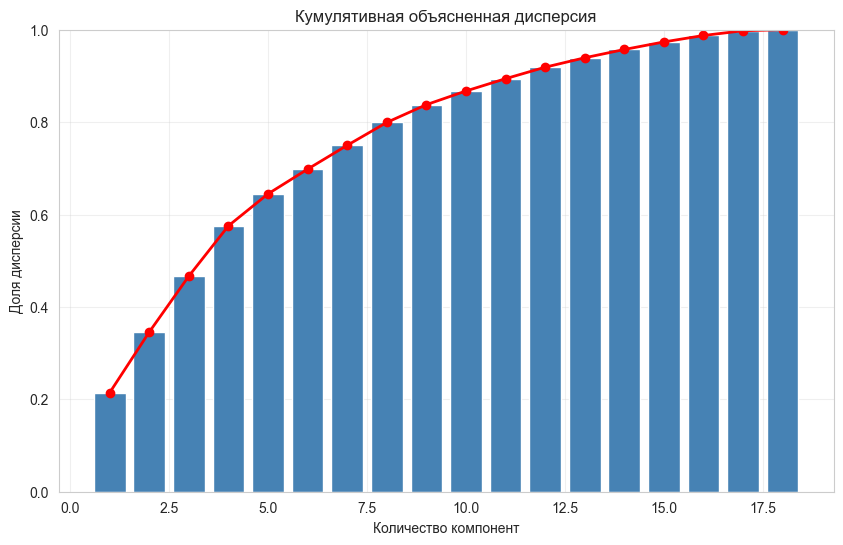

In [21]:
cumulative_var = np.cumsum(eigenvalues) / eigenvalues.sum()

plt.figure(figsize=(10, 6))
plt.bar(range(1, len(cumulative_var)+1), cumulative_var, color='steelblue')
plt.plot(range(1, len(cumulative_var)+1), cumulative_var, 'ro-', linewidth=2)
plt.title('Кумулятивная объясненная дисперсия')
plt.xlabel('Количество компонент')
plt.ylabel('Доля дисперсии')
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.show()

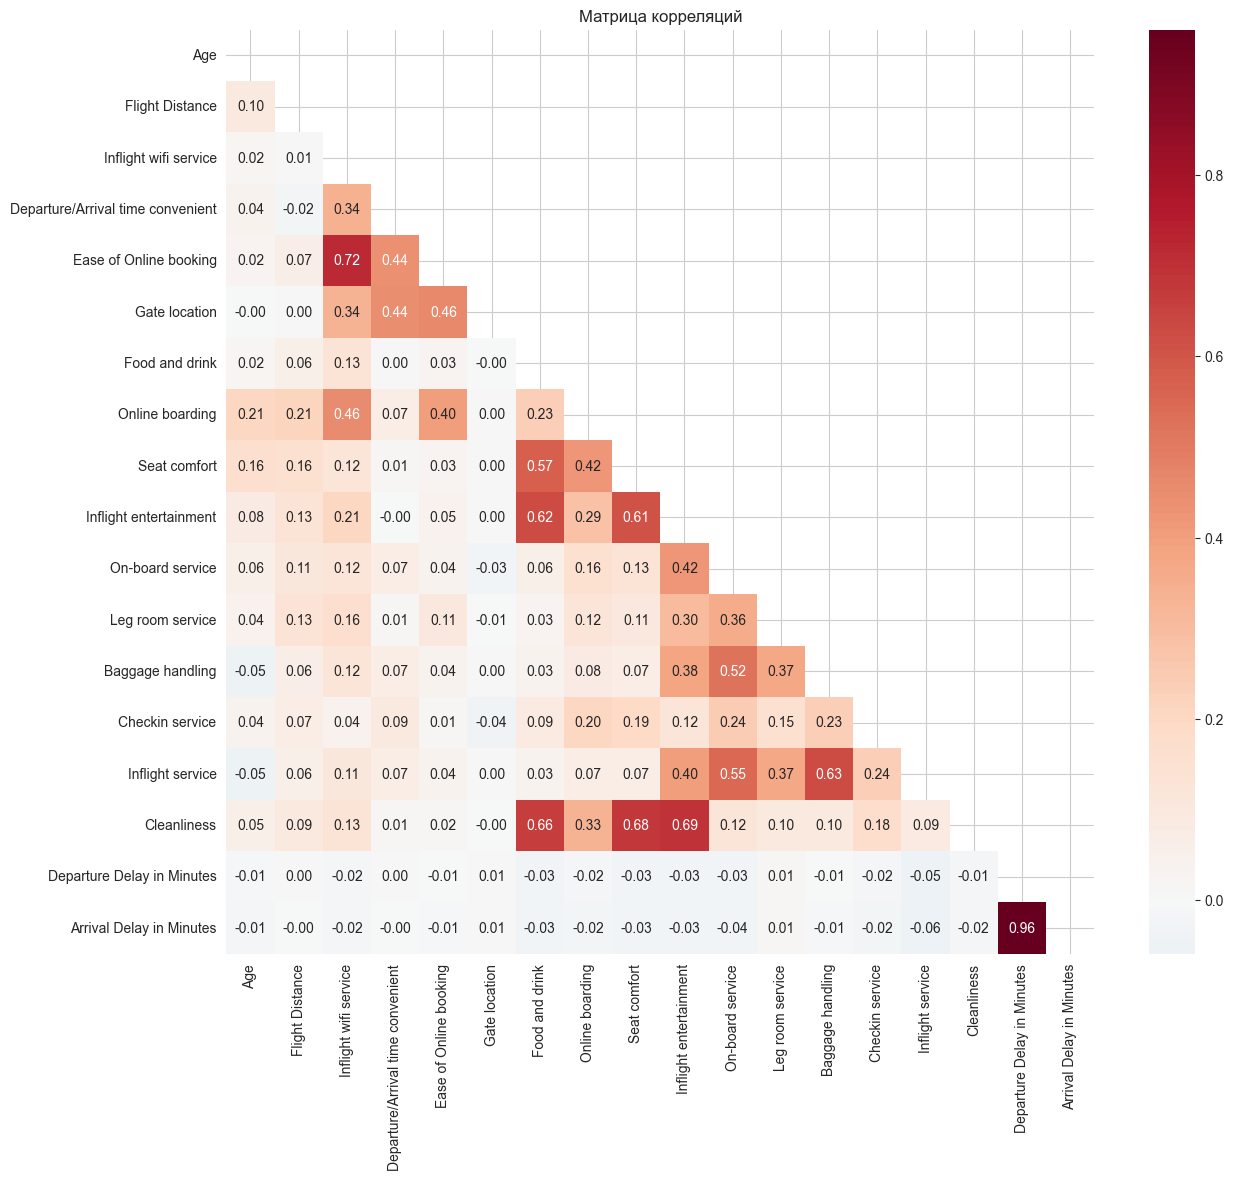

In [22]:
plt.figure(figsize=(14, 12))
corr_matrix = df_numeric.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('Матрица корреляций')
plt.show()